<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/Design_400_Qubits_Programmatically_with_GPU_Acceleration_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# Four-Hundred-Qubit Array with CuPy and OASIS

The array uses native `TransmonPocket` qubits in independent vertical bus chains, with one multiplexed readout feedline per column.

Each qubit keeps the tutorial's two capacitor islands, four corner connection pads, −90° orientation, 3 mm lattice pitch, and alternating 1.5 mm column offset. A central 120 × 30 µm side pad adds the readout interface to the left island with a 15 µm capacitive gap. Native `RouteMeander` buses join `B0` of each lower qubit to `B3` of the qubit above it; the remaining corner pads end in native open terminations.

## Layout parameters

| Parameter | Value or Quantum Metal option |
| --- | --- |
| Array controls | `N_X=20`, `N_Y=20`; qubit count is `N_X*N_Y` |
| Chip controls | `CHIP_SIZE_X=f"{3*(N_X+1)}mm"`, `CHIP_SIZE_Y=f"{3*(N_Y+1)}mm"`; either control also accepts a fixed size |
| Qubit placement | 3 mm pitch; odd columns shifted upward by 1.5 mm; source chip-center offset subtracted |
| Pocket qubit | Native `TransmonPocket`; 455 × 90 µm island rectangles, 30 µm island gap, 650 × 650 µm pocket |
| Corner pad widths | `B0=75um`, `B1=120um`, `B2=120um`, `B3=90um`; 30 µm pad height |
| Readout pad | 120 µm along the island, 30 µm radial width, 15 µm island gap; 10/6 µm CPW exits the west pocket wall |
| Bus topology | One passive chain per column; `N_X*(N_Y-1)` quantum buses |
| Quantum buses | 7.0 and 7.5 mm alternating by row; 10 µm trace, 6 µm slots, 99 µm fillets |
| Bus leads and meanders | 500/250 µm endpoint leads; 200 µm spacing; −700 µm asymmetry |
| Readout targets | Evenly spaced from 6.4 to 6.8 GHz in each column; a single-row array uses 6.6 GHz |
| Readout model | Phase velocity $v_p=1.20\times10^8$ m/s; total quarter-wave length includes the coupled arm and circular bends |
| Readout meanders | 10 µm trace, 6 µm slots, 70 µm fillets, 160 µm spacing, 140/180 µm leads |
| Readout coupled-line tees | 200 µm coupling length, 150 µm exit leg, 50 µm fillets; shorted secondary termination |
| Readout coupling gap | 15.1 µm metal-edge separation: 5.1 µm slot + 4 µm ground strip + 6 µm slot |
| Column feedlines | 11.7 µm trace, 5.1 µm slots; 1.3 mm west of each qubit column |
| Launcher placement | Top and bottom chip edges; outer pad metal 100 µm inside the footprint |
| Launcher geometry | 160 µm width, 200 µm body, 200 µm taper, 25 µm lead, 58 µm ground gap |
| Series capacitor control | `INLINE_CAPACITORS=True`; `False` joins launchers directly to their feedline |
| Series capacitors | Native two-terminal `CapNInterdigital` in the center-conductor path; five 20 µm fingers, 10 µm width, 6 µm gaps |
| Ground cheesing | Native 25 × 25 µm holes, 100 µm pitch; `CHEESE_KEEPOUT="50um"` sets the native component buffer |
| Chip-edge cheese clearance | Hole edges at least 100 µm inside every chip edge |
| Layout layer 1 | Positive ground, islands, CPW circuit, and launcher electrodes |
| Layout layer 9 | Symbolic 20 × 30 µm lumped-junction markers |
| File precision | 1 nm |
| Default output | `400_Qubits_Quantum_Metal.oas`; change the filename suffix to `.gds` for GDSII |
| Numerical backend | CuPy on an available CUDA GPU; NumPy on CPU |
| Precision for numerical batches | Float64, including the polygon-area audit |
| Native CAD backend | Quantum Metal 0.9.0; component creation, routing, design rules, and cheesing run on CPU |
| Export | Native in-memory geometry; one GDSTK write, with OASIS compression level 1 |

The column-chain topology places the buses and readout circuit in one conductor plane. The default array has 380 passive quantum buses, 400 readout resonators, 20 readout feedlines, 40 inline series capacitors, and 40 perimeter launchers. Each column holds an independent twenty-qubit bus chain; the lateral connection pads end in native open terminations to keep the ground connected without airbridges.

$$
\ell_r=\frac{v_p}{4f_r}=\ell_{\mathrm{meander}}+\ell_{\mathrm{tee}},\qquad \ell_{\mathrm{tee}}=\ell_{\mathrm{raw}}-\left(2-\frac{\pi}{2}\right)r_f.
$$

Here $f_r$ denotes a readout target, $\ell_r$ denotes its open-to-short centerline, and $r_f=50$ µm denotes the coupled-arm bend radius. The uniform-line estimate sets initial geometry; a loaded electromagnetic model includes the island capacitances, coupled sections, material properties, and package. The source's bus lengths remain geometric design targets, while layer 9 holds symbolic junction sheets. Stage timings separate numerical work, native construction, design rules, geometry preparation, and file writing; they report the runtime actually used.

## Documentation

[TransmonPocket](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.TransmonPocket.html) · [CoupledLineTee](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.CoupledLineTee.html) · [CapNInterdigital](https://qiskit-community.github.io/qiskit-metal/apidocs/qiskit_metal.qlibrary.CapNInterdigital.html) · [RouteMeander](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.12-Simple-Meander.html) · [Native design rules](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.24-Design-rule-checking.html) · [Native cheesing and GDS export](https://qiskit-community.github.io/qiskit-metal/tut/3-Renderers/3.2-Export-your-design-to-GDS.html)


[CuPy installation](https://docs.cupy.dev/en/stable/install.html) · [CuPy arrays](https://docs.cupy.dev/en/stable/overview.html) · [GDSTK OASIS export](https://heitzmann.github.io/gdstk/library/gdstk.Library.html#gdstk.Library.write_oas) · [Quantum Metal renderer source](https://qiskit-community.github.io/qiskit-metal/_modules/qiskit_metal/renderers/renderer_gds/gds_renderer.html)


In [1]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip uninstall -q cupy-cuda13x cupy-cuda12x cupy
!uv pip install -q quantum-metal cupy-cuda12x

In [2]:
"""This script builds a qubit array with CuPy batches and native OASIS export."""

# Control Knobs
N_X = 20
N_Y = 20
CHIP_SIZE_X = f"{3 * (N_X + 1)}mm"
CHIP_SIZE_Y = f"{3 * (N_Y + 1)}mm"
CHEESE_KEEPOUT = "50um"
INLINE_CAPACITORS = True
OUTPUT_FILENAME = "400_Qubits.oas"

# Imports and Design
from importlib.metadata import version
import logging
import os
from pathlib import Path
from time import perf_counter
import warnings

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

import gdstk
from IPython.display import display
from IPython.display import FileLink
from matplotlib.collections import PolyCollection
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit_metal as qm
from qiskit_metal import designs
from qiskit_metal import Dict
from qiskit_metal import draw
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.lumped.cap_n_interdigital import CapNInterdigital
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer
from qiskit_metal.validation import DEFAULT_RULES
from qiskit_metal.validation import SHAPE_RULES
from qiskit_metal.validation import validate

qm.logger.setLevel(logging.WARNING)
warnings.filterwarnings("ignore")

assert isinstance(N_X, int) and isinstance(N_Y, int)
assert N_X >= 1 and N_Y >= 1
design = designs.DesignPlanar(overwrite_enabled=True, enable_renderers=False)
design.chips.main.size.size_x = CHIP_SIZE_X
design.chips.main.size.size_y = CHIP_SIZE_Y
design.variables.cpw_width = "10um"
design.variables.cpw_gap = "6um"
gds_renderer = QGDSRenderer(design)
design.renderers.gds = gds_renderer
chip_x = float(design.parse_value(CHIP_SIZE_X))
chip_y = float(design.parse_value(CHIP_SIZE_Y))

# Numerical Backend and Batched Plan
assert version("quantum-metal") == "0.9.0", "Run the installation cell."
script_started = perf_counter()
timings = []
xp = np
backend = "NumPy (CPU)"
try:
    import cupy as cp

    if cp.is_available():
        cp.arange(4, dtype=cp.float64).sum().item()
        xp = cp
        backend = "CuPy (CUDA GPU)"
except (ImportError, RuntimeError, OSError) as error:
    backend = f"NumPy (CPU; {type(error).__name__})"

plan_started = perf_counter()
ix, iy = xp.indices((N_X, N_Y), dtype=xp.int64)
frequency_gpu = xp.linspace(6.4, 6.8, N_Y) if N_Y > 1 else xp.asarray([6.6])
plan_gpu = xp.stack(
    (
        3.0 * ix - 1.5 * (N_X - 1),
        3.0 * iy + 1.5 * (ix % 2) - 1.5 * (N_Y - 1) - 0.75 * (N_X > 1),
        xp.broadcast_to(1.20e8 / (4.0 * frequency_gpu * 1e6), (N_X, N_Y)),
    ),
    axis=-1,
).astype(xp.float64)
plan = cp.asnumpy(plan_gpu) if xp is not np else np.asarray(plan_gpu)
readout_frequencies = (
    cp.asnumpy(frequency_gpu) if xp is not np else frequency_gpu
)
assert np.isfinite(plan).all()
timings.append(
    {"stage": "Numerical plan", "seconds": perf_counter() - plan_started}
)
print(f"Numerical backend: {backend}")
qubits, couplers = {}, {}
buses, resonators, feedlines, launchpads, end_caps = [], [], [], [], []
bus_records, readout_records, sites = [], [], []
print(f"Quantum Metal {version('quantum-metal')}")

Numerical backend: CuPy (CUDA GPU)
Quantum Metal 0.9.0


In [3]:
components_started = perf_counter()

# --- Staggered Pocket-Qubit Array ---
for x in range(N_X):
    for y in range(N_Y):
        qx, qy = plan[x, y, :2]
        qubit = TransmonPocket(
            design, f"Q_{x}_{y}",
            options=Dict(
                pos_x=f"{qx}mm", pos_y=f"{qy}mm", orientation="-90", layer="1",
                pad_width="455um", pad_height="90um", pad_gap="30um",
                pocket_width="650um", pocket_height="650um",
                connection_pads=Dict(
                    B0=Dict(loc_W=-1, loc_H=-1, pad_width="75um"),
                    B1=Dict(loc_W=-1, loc_H=1, pad_width="120um"),
                    B2=Dict(loc_W=1, loc_H=-1, pad_width="120um"),
                    B3=Dict(loc_W=1, loc_H=1, pad_width="90um"),
                ),
            ),
        )
        # A side pad couples the left island to its readout resonator.
        readout_wire = draw.LineString([[qx - 0.150, qy], [qx - 0.425, qy]])
        qubit.add_qgeometry(
            "poly", {"readout_pad": draw.rectangle(0.030, 0.120, qx - 0.135, qy)},
            layer=1,
        )
        qubit.add_qgeometry("path", {"readout_trace": readout_wire}, width=0.010, layer=1)
        qubit.add_qgeometry("path", {"readout_cut": readout_wire}, width=0.022,
                            layer=1, subtract=True)
        qubit.add_pin("readout", points=np.array(readout_wire.coords),
                      width=0.010, input_as_norm=True)
        qubits[x, y] = qubit
        sites.append((qubit.name, qx, qy))

# --- Passive Column Buses ---
for x in range(N_X):
    for y in range(N_Y - 1):
        target_length = 7.0 + 0.5 * (y % 2)
        bus = RouteMeander(
            design, f"Bus_{x}_{y}",
            options=Dict(
                layer="1", trace_width="10um", trace_gap="6um",
                total_length=f"{target_length}mm", fillet="99um",
                pin_inputs=Dict(
                    start_pin=Dict(component=qubits[x, y].name, pin="B0"),
                    end_pin=Dict(component=qubits[x, y + 1].name, pin="B3"),
                ),
                lead=Dict(start_straight="500um", end_straight="250um"),
                meander=Dict(spacing="200um", asymmetry="-700um"),
                prevent_short_edges="true",
            ),
        )
        buses.append(bus)
        bus_records.append({"bus": bus.name, "target_mm": target_length,
                            "actual_mm": bus.length})

# --- Coupled-Line Readout Resonators ---
for x in range(N_X):
    for y in range(N_Y):
        qubit = qubits[x, y]
        qx, qy = qubit.p.pos_x, qubit.p.pos_y
        tee = CoupledLineTee(
            design, f"CLT_{x}_{y}",
            options=Dict(
                pos_x=f"{qx - 1.300}mm", pos_y=f"{qy - 0.100}mm",
                orientation="90", layer="1", prime_width="11.7um", prime_gap="5.1um",
                second_width="10um", second_gap="6um",
                coupling_length="200um", coupling_space="4um",
                down_length="150um", fillet="50um", open_termination=False,
            ),
        )
        secondary = tee.qgeometry_table("path")
        secondary = secondary[secondary.name == "second_cpw"].iloc[0]
        arm_length = secondary.geometry.length - (2 - np.pi / 2) * secondary.fillet
        target_length = float(plan[x, y, 2])
        resonator = RouteMeander(
            design, f"Readout_{x}_{y}",
            options=Dict(
                layer="1", trace_width="10um", trace_gap="6um", fillet="70um",
                total_length=f"{target_length - arm_length}mm",
                pin_inputs=Dict(
                    start_pin=Dict(component=qubit.name, pin="readout"),
                    end_pin=Dict(component=tee.name, pin="second_end"),
                ),
                lead=Dict(start_straight="140um", end_straight="180um"),
                meander=Dict(spacing="160um", asymmetry="0um"),
                prevent_short_edges="true",
            ),
        )
        couplers[x, y] = tee
        resonators.append(resonator)
        actual_length = resonator.length + arm_length
        readout_records.append({
            "qubit": qubit.name, "target_GHz": readout_frequencies[y],
            "length_mm": actual_length, "model_GHz": 1.20e8 / (4 * actual_length * 1e6),
        })

# --- Column Feedlines and Perimeter Ports ---
for x in range(N_X):
    feed_x = qubits[x, 0].p.pos_x - 1.300
    ports = []
    port_pin = "north_end" if INLINE_CAPACITORS else "tie"
    for tag, side in (("Bottom", -1), ("Top", 1)):
        pad = LaunchpadWirebond(
            design, f"Pad_{x}_{tag}",
            options=Dict(
                pos_x=f"{feed_x}mm", pos_y=f"{side * (chip_y / 2 - 0.500)}mm",
                orientation="90" if side == -1 else "-90", layer="1",
                trace_width="11.7um", trace_gap="5.1um", lead_length="25um",
                pad_width="160um", pad_height="200um", taper_height="200um",
                pad_gap="58um",
            ),
        )
        launchpads.append(pad)
        if INLINE_CAPACITORS:
            cap = CapNInterdigital(
                design, f"FeedCap_{x}_{tag}",
                options=Dict(
                    pos_x=f"{feed_x}mm", pos_y=f"{side * (chip_y / 2 - 1.073)}mm",
                    orientation="0" if side == -1 else "180", layer="1",
                    north_width="11.7um", north_gap="5.1um",
                    south_width="11.7um", south_gap="5.1um",
                    cap_width="10um", cap_gap="6um", cap_gap_ground="6um",
                    finger_length="20um", finger_count="5", cap_distance="50um",
                ),
            )
            ports.append(cap)
            end_caps.append(cap)
            feedlines.append(RouteStraight(
                design, f"PortLine_{x}_{tag}",
                options=Dict(layer="1", trace_width="11.7um", trace_gap="5.1um",
                             pin_inputs=Dict(
                                 start_pin=Dict(component=pad.name, pin="tie"),
                                 end_pin=Dict(component=cap.name, pin="south_end"),
                             )),
            ))
        else:
            ports.append(pad)
    connections = [(ports[0], port_pin, couplers[x, 0], "prime_start")]
    connections += [(couplers[x, y], "prime_end", couplers[x, y + 1], "prime_start")
                    for y in range(N_Y - 1)]
    connections.append((couplers[x, N_Y - 1], "prime_end", ports[1], port_pin))
    for index, (start, start_pin, end, end_pin) in enumerate(connections):
        feedlines.append(RouteStraight(
            design, f"Feedline_{x}_{index}",
            options=Dict(layer="1", trace_width="11.7um", trace_gap="5.1um",
                         pin_inputs=Dict(
                             start_pin=Dict(component=start.name, pin=start_pin),
                             end_pin=Dict(component=end.name, pin=end_pin),
                         )),
        ))

# --- Open Unused Corner Pads ---
for qubit in qubits.values():
    for name in ("B0", "B1", "B2", "B3"):
        pin = qubit.pins[name]
        if pin.net_id == 0:
            angle = np.degrees(np.arctan2(pin.normal[1], pin.normal[0]))
            termination = OpenToGround(
                design, f"Open_{qubit.name}_{name}",
                options=Dict(pos_x=f"{pin.middle[0]}mm", pos_y=f"{pin.middle[1]}mm",
                             orientation=str(angle), layer="1", width="10um", gap="6um"),
            )
            design.connect_pins(qubit.id, name, termination.id, "open")

# --- Symbolic Junction Markers ---
junction_table = design.qgeometry.tables["junction"].copy(deep=True)
for _, junction in junction_table.iterrows():
    owner = design._components[int(junction.component)]
    owner.add_qgeometry(
        "poly", {"junction_marker": junction.geometry.buffer(
            float(junction.width) / 2, cap_style=2,
        )}, layer=9,
    )

timings.append({"stage": "Native components and routes",
                "seconds": perf_counter() - components_started})

# --- Native Routing and Geometry Checks ---
checks_started = perf_counter()
drc = validate(design, rules=[*DEFAULT_RULES, *SHAPE_RULES])
print(drc.report())
drc.raise_if_errors()
bus_table = pd.DataFrame(bus_records, columns=["bus", "target_mm", "actual_mm"])
readout_table = pd.DataFrame(readout_records)
assert bus_table.empty or (bus_table.actual_mm - bus_table.target_mm).abs().max() < 1e-6
assert (readout_table.model_GHz - readout_table.target_GHz).abs().max() < 1e-8
# Batch every route edge in one CPU-to-GPU transfer.
route_list = buses + resonators + feedlines
route_points = [route.get_points() for route in route_list]
edge_arrays = [np.diff(points, axis=0) for points in route_points]
required_lengths = [np.full(len(points) - 1, 2 * float(route.p.fillet))
                    for route, points in zip(route_list, route_points)]
for minimums, route in zip(required_lengths, route_list):
    minimums[[0, -1]] = float(route.p.fillet)
edge_vectors = xp.asarray(np.concatenate(edge_arrays), dtype=xp.float64)
minimums = xp.asarray(np.concatenate(required_lengths), dtype=xp.float64)
assert bool(xp.all(xp.linalg.norm(edge_vectors, axis=1) >= minimums - 1e-9)), \
    "A route segment is too short for its fillets."
for pad in launchpads:
    metal = pad.qgeometry_table("poly")
    xmin, ymin, xmax, ymax = metal[~metal["subtract"]].geometry.union_all().bounds
    edge_distance = min(xmin + chip_x / 2, ymin + chip_y / 2,
                        chip_x / 2 - xmax, chip_y / 2 - ymax)
    assert np.isclose(edge_distance, 0.100, atol=1e-6), pad.name
display(bus_table)
display(readout_table)
print(f"{len(qubits)} qubits; {len(buses)} quantum buses; {len(resonators)} readouts; "
      f"{N_X} feedlines; {len(launchpads)} launchpads")
timings.append({"stage": "Native DRC and batched checks",
                "seconds": perf_counter() - checks_started})

Design rules passed (12 rules ran, no findings).


,bus,target_mm,actual_mm
0,Bus_0_0,7.0,7.0
1,Bus_0_1,7.5,7.5
2,Bus_0_2,7.0,7.0
3,Bus_0_3,7.5,7.5
4,Bus_0_4,7.0,7.0
...,...,...,...
375,Bus_19_14,7.0,7.0
376,Bus_19_15,7.5,7.5
377,Bus_19_16,7.0,7.0
378,Bus_19_17,7.5,7.5


,qubit,target_GHz,length_mm,model_GHz
0,Q_0_0,6.400000,4.687500,6.400000
1,Q_0_1,6.421053,4.672131,6.421053
2,Q_0_2,6.442105,4.656863,6.442105
3,Q_0_3,6.463158,4.641694,6.463158
4,Q_0_4,6.484211,4.626623,6.484211
...,...,...,...,...
395,Q_19_15,6.715789,4.467085,6.715789
396,Q_19_16,6.736842,4.453125,6.736842
397,Q_19_17,6.757895,4.439252,6.757895
398,Q_19_18,6.778947,4.425466,6.778947


400 qubits; 380 quantum buses; 400 readouts; 20 feedlines; 40 launchpads


,layer,vertices,source_mm2,saved_mm2,error_mm2
0,1,6836797,3585.246299,3585.246359,6.066494e-05
1,9,2000,0.240000,0.240000,1.164985e-12


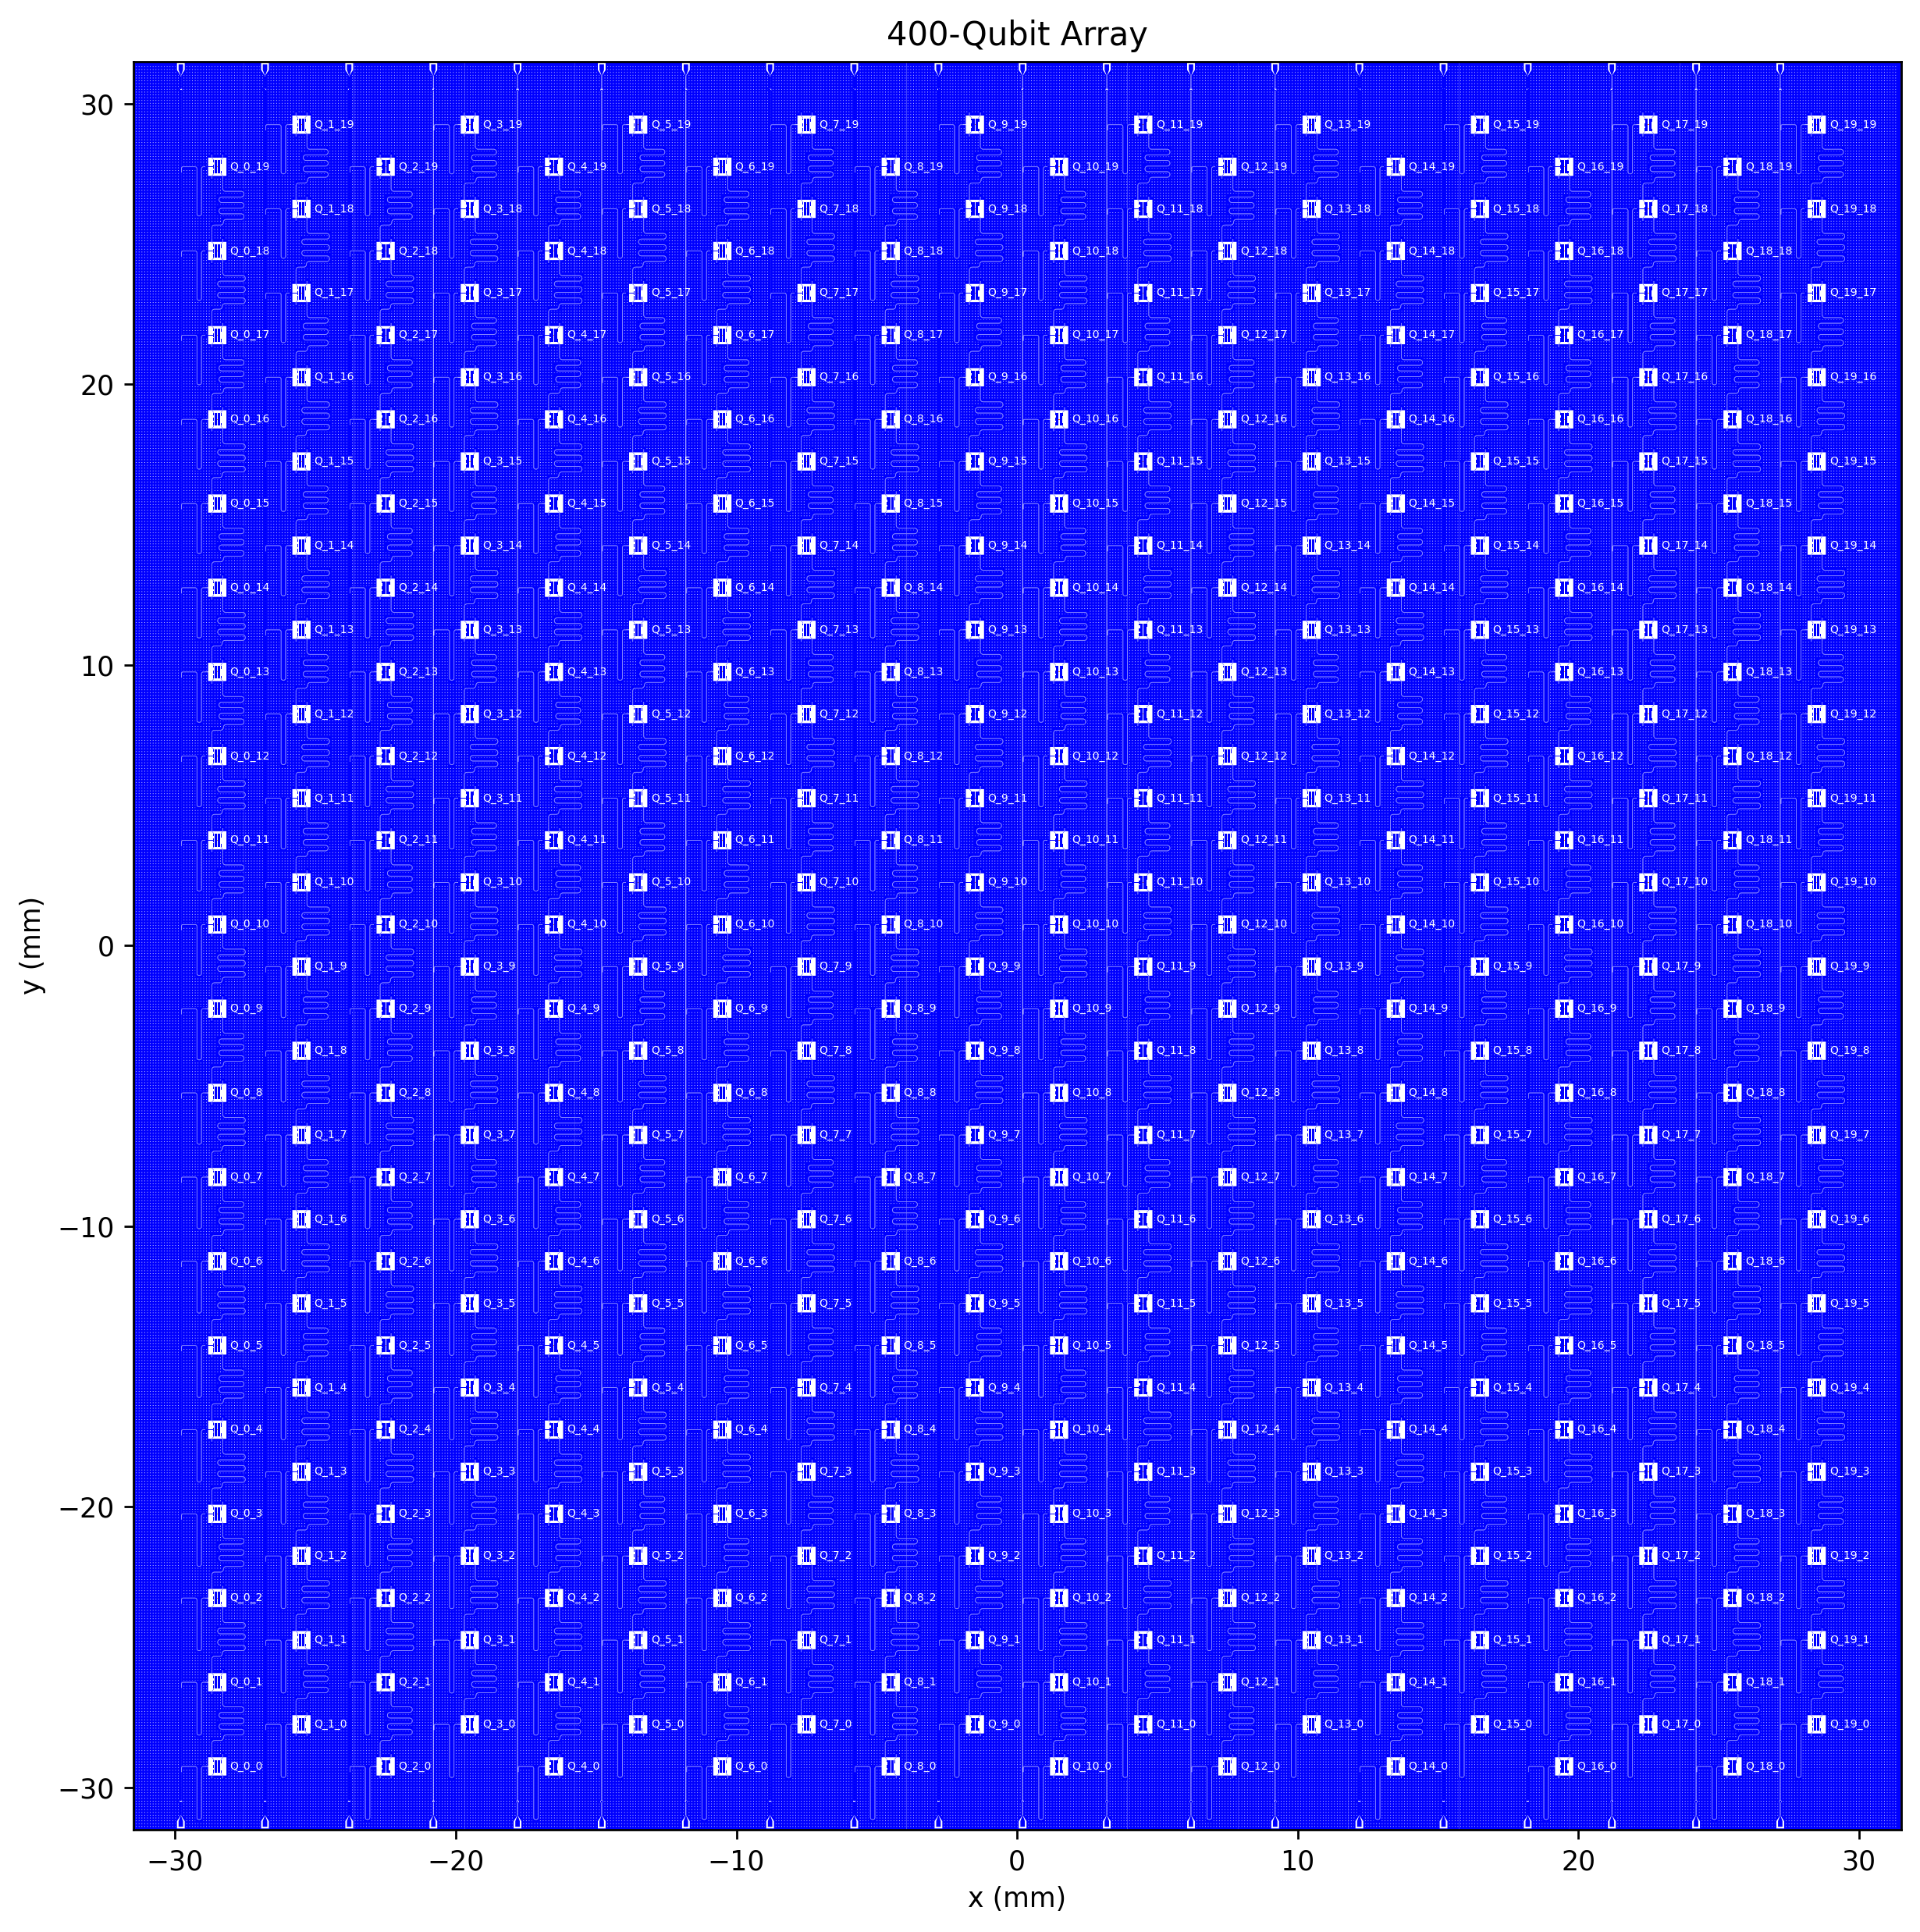

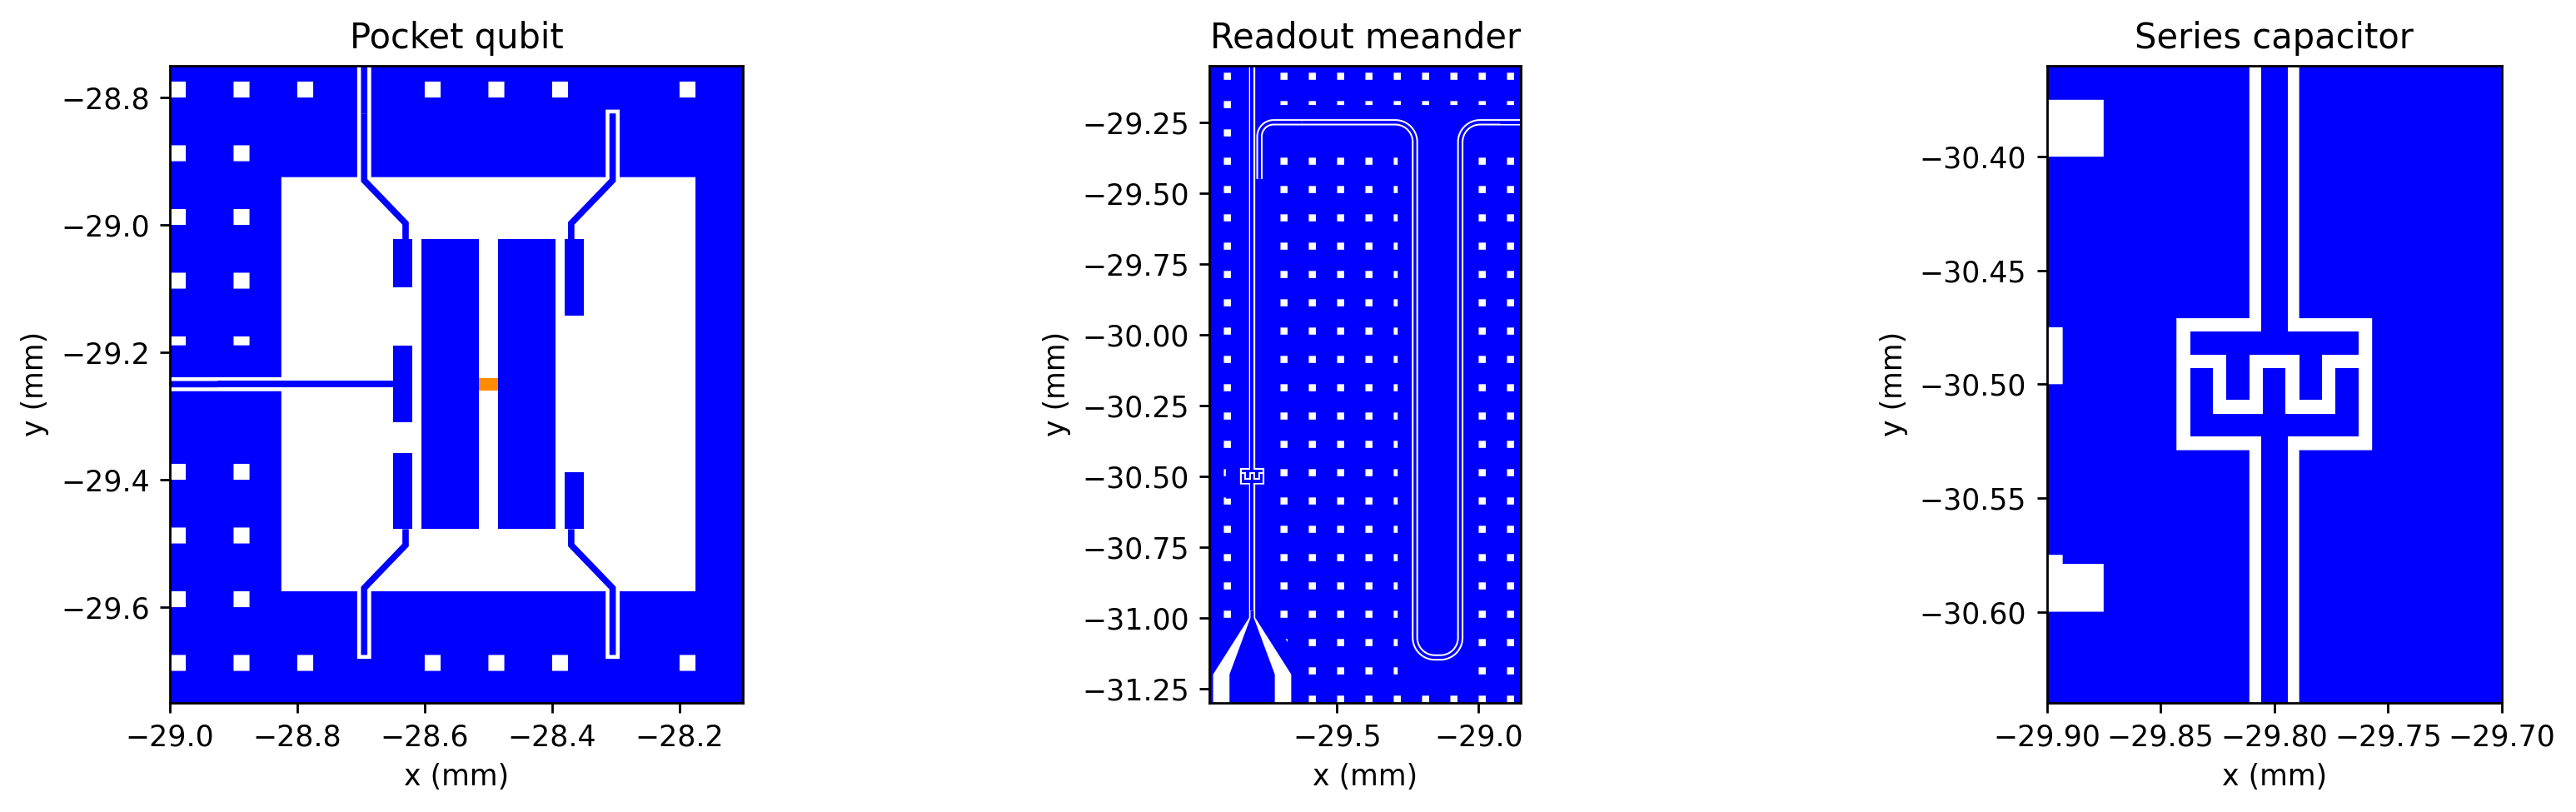

,stage,seconds
0,Numerical plan,1.595
1,Native components and routes,101.115
2,Native DRC and batched checks,62.165
3,Native geometry and cheesing,242.913
4,File writing,0.378
5,Readback and polygon audit,6.229
6,Previews,5.096
7,Native geometry and cheesing,244.924
8,File writing,0.380
9,Readback and polygon audit,0.674


Pipeline: 703.50 s
OAS: 400_Qubits.oas (2,242,805 bytes)
Layers: 1 = positive ground/circuit; 9 = symbolic junction markers


/content/400_Qubits.oas

In [5]:
# --- Native Cheesing and Direct Export ---
out = Path.cwd() / OUTPUT_FILENAME
assert out.suffix.lower() in (".oas", ".oasis", ".gds")
gds_renderer.options.precision = "1e-9"
gds_renderer.options.max_points = "8190"
gds_renderer.options.tolerance = "1e-6"
gds_renderer.options.fabricate = "True"
gds_renderer.options.short_segments_to_not_fillet = "False"
gds_renderer.options.path_filename = ""
gds_renderer.options.cheese = QGDSRenderer.default_options.cheese.copy()
gds_renderer.options.no_cheese = QGDSRenderer.default_options.no_cheese.copy()
gds_renderer.options.no_cheese.buffer = CHEESE_KEEPOUT
gds_renderer.options.cheese.edge_nocheese = "112.5um"
gds_renderer.options.cheese.view_in_file = Dict(main={1: True, 9: False})
gds_renderer.options.no_cheese.view_in_file = Dict(main={1: False, 9: False})

# Prepare Quantum Metal's geometry in memory, before either file writer.
geometry_started = perf_counter()
junction_table = design.qgeometry.tables["junction"].copy(deep=True)
design.qgeometry.tables["junction"] = junction_table.iloc[:0].copy()
previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    gds_renderer.chip_info.clear()
    gds_renderer.chip_info.update(gds_renderer._get_chip_names())
    gds_renderer.imported_junction_gds = None
    assert gds_renderer._create_qgeometry_for_gds([]) == 0
    gds_renderer._populate_poly_path_for_export()
    gds_renderer._populate_no_cheese()
    gds_renderer._populate_cheese()
finally:
    qm.logger.setLevel(previous_log_level)
    design.qgeometry.tables["junction"] = junction_table

cell_names = {cell.name for cell in gds_renderer.lib.cells}
for cell in gds_renderer.lib.cells:
    for reference in list(cell.references):
        if reference.cell_name not in cell_names:
            cell.remove(reference)
timings.append({"stage": "Native geometry and cheesing",
                "seconds": perf_counter() - geometry_started})

write_started = perf_counter()
if out.suffix.lower() in (".oas", ".oasis"):
    gds_renderer.lib.write_oas(str(out), compression_level=1, validation="crc32")
else:
    gds_renderer.lib.write_gds(str(out), max_points=8190)
timings.append({"stage": "File writing", "seconds": perf_counter() - write_started})
assert out.is_file() and out.stat().st_size > 0

# --- Readback and Batched Polygon-Area Audit ---
audit_started = perf_counter()
verified_layout = (gdstk.read_oas(str(out), unit=gds_renderer.lib.unit) if out.suffix.lower() in (".oas", ".oasis")
                   else gdstk.read_gds(str(out)))
top_cells = verified_layout.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {polygon.layer for polygon in exported_polygons} == {1, 9}
assert sum(polygon.layer == 9 for polygon in exported_polygons) == N_X * N_Y
assert np.isclose(verified_layout.precision, 1e-9, rtol=1e-12, atol=0)
assert np.allclose(top_cells[0].bounding_box(),
                   [[-chip_x / 2, -chip_y / 2], [chip_x / 2, chip_y / 2]])
source_polygons = gds_renderer.lib.top_level()[0].get_polygons()
area_records = []
for layer in (1, 9):
    polygons = [polygon for polygon in source_polygons if polygon.layer == layer]
    arrays = [polygon.points for polygon in polygons]
    counts = xp.asarray([len(points) for points in arrays], dtype=xp.int64)
    vertices = xp.asarray(np.concatenate(arrays), dtype=xp.float64)
    ends = xp.cumsum(counts)
    starts = xp.concatenate((xp.zeros(1, dtype=xp.int64), ends[:-1]))
    following = xp.roll(vertices, -1, axis=0)
    following[ends - 1] = vertices[starts]
    cross_products = vertices[:, 0] * following[:, 1] - following[:, 0] * vertices[:, 1]
    polygon_ids = xp.repeat(xp.arange(len(polygons), dtype=xp.int64), counts)
    areas = 0.5 * xp.abs(xp.bincount(polygon_ids, weights=cross_products,
                                   minlength=len(polygons)))
    source_area = float(areas.sum())
    saved_area = sum(polygon.area() for polygon in exported_polygons
                     if polygon.layer == layer)
    quantum = verified_layout.precision / verified_layout.unit
    tolerance = max(1e-7, 2 * quantum * sum(polygon.perimeter() for polygon in polygons))
    assert abs(source_area - saved_area) <= tolerance, f"Layer {layer} area changed."
    area_records.append({"layer": layer, "vertices": int(vertices.shape[0]),
                         "source_mm2": source_area, "saved_mm2": saved_area,
                         "error_mm2": abs(source_area - saved_area)})
    del vertices, following, cross_products, polygon_ids, areas, counts, starts, ends
if xp is not np:
    cp.get_default_memory_pool().free_all_blocks()
timings.append({"stage": "Readback and polygon audit",
                "seconds": perf_counter() - audit_started})
display(pd.DataFrame(area_records))

# --- In-Memory Chip Preview ---
preview_started = perf_counter()
fig, ax = plt.subplots(figsize=(12, 10), dpi=250)
for layer, color in ((1, "#0000FF"), (9, "#ff8c00")):
    ax.add_collection(PolyCollection(
        [polygon.points for polygon in exported_polygons if polygon.layer == layer],
        facecolor=color, edgecolor="none", rasterized=True,
    ))
ax.set_aspect("equal")
ax.set_xlim(-chip_x / 2, chip_x / 2)
ax.set_ylim(-chip_y / 2, chip_y / 2)
ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_title("400-Qubit Array", fontfamily="DejaVu Sans", weight="normal")
for name, x, y in sites:
    ax.text(x + 0.450, y, name, fontsize=4, ha="left", va="center", color="white",
            fontfamily="DejaVu Sans", weight="normal")
fig.tight_layout()
plt.show()

# --- In-Memory Component Previews ---
detail_fig, detail_axes = plt.subplots(1, 3, figsize=(14, 4), dpi=250)
qubit = qubits[0, 0]
qx, qy = qubit.p.pos_x, qubit.p.pos_y
if INLINE_CAPACITORS:
    cap = end_caps[0]
    port_center = (cap.pins.north_end.middle + cap.pins.south_end.middle) / 2
else:
    port_center = launchpads[0].pins.tie.middle
views = (
    ((qx - 0.50, qx + 0.40), (qy - 0.50, qy + 0.50), "Pocket qubit"),
    ((qx - 1.45, qx - 0.35), (qy - 2.05, qy + 0.20), "Readout meander"),
    ((port_center[0] - 0.10, port_center[0] + 0.10),
     (port_center[1] - 0.14, port_center[1] + 0.14),
     "Series capacitor" if INLINE_CAPACITORS else "Direct port"),
)
for ax, (xlimits, ylimits, title) in zip(detail_axes, views):
    for layer, color in ((1, "#0000FF"), (9, "#ff8c00")):
        ax.add_collection(PolyCollection(
            [polygon.points for polygon in exported_polygons if polygon.layer == layer],
            facecolor=color, edgecolor="none", rasterized=True,
        ))
    ax.set_aspect("equal")
    ax.set_xlim(*xlimits)
    ax.set_ylim(*ylimits)
    ax.set_title(title, fontfamily="DejaVu Sans", weight="normal")
    ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.ticklabel_format(useOffset=False)
detail_fig.tight_layout()
plt.show()
timings.append({"stage": "Previews", "seconds": perf_counter() - preview_started})
display(pd.DataFrame(timings).round(3))
print(f"Pipeline: {perf_counter() - script_started:.2f} s")
print(f"{out.suffix[1:].upper()}: {out.name} ({out.stat().st_size:,} bytes)")
print("Layers: 1 = positive ground/circuit; 9 = symbolic junction markers")
display(FileLink(str(out)))